In [1]:
import io
import os
import zipfile
import numpy as np
import pandas as pd
import requests

# 1. URL oficial do dataset SECOM na UCI
url = "https://archive.ics.uci.edu/static/public/179/secom.zip"

print("Baixando o dataset SECOM...")
response = requests.get(url)
response.raise_for_status()  # Garante que o download ocorreu sem erros

# 2. Extração do conteúdo do arquivo ZIP
extracted_dir = "secom_extracted"
os.makedirs(extracted_dir, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
  z.extractall(extracted_dir)
  print("Arquivos extraídos com sucesso!")

# 3. Localizando os arquivos extraídos (lidando com possíveis subpastas)
data_path, labels_path = None, None
for root, dirs, files in os.walk(extracted_dir):
  if "secom.data" in files:
    data_path = os.path.join(root, "secom.data")
  if "secom_labels.data" in files:
    labels_path = os.path.join(root, "secom_labels.data")

if not data_path or not labels_path:
  raise FileNotFoundError(
      "Não foi possível localizar 'secom.data' ou 'secom_labels.data' após a"
      " extração."
  )

# 4. Carregamento dos dados dos sensores
# O dataset utiliza espaços em branco como separadores e possui valores ausentes
print("Processando os dados dos sensores...")
df_features = pd.read_csv(data_path, sep=r"\s+", header=None)

# Renomeando as colunas para o padrão Sensor_1, Sensor_2, ...
df_features.columns = [f"Sensor_{i+1}" for i in range(df_features.shape[1])]

# 5. Carregamento dos rótulos (Target) e timestamps
print("Processando os rótulos e timestamps...")
df_labels = pd.read_csv(labels_path, sep=r"\s+", header=None)

# Coluna 0: Pass/Fail (-1 = Pass, 1 = Fail) | Coluna 1: Timestamp
df_features["Target"] = df_labels[0]
df_features["Timestamp"] = df_labels[1]

# 6. Exibição das informações básicas do DataFrame resultante
print("\nDataset pronto para uso!")
print(f"Dimensões do DataFrame: {df_features.shape}")
print("\nDistribuição das classes (Target):")
print(df_features["Target"].value_counts())

# Exibe as primeiras linhas no Jupyter Notebook
df_features.head()

Baixando o dataset SECOM...
Arquivos extraídos com sucesso!
Processando os dados dos sensores...
Processando os rótulos e timestamps...

Dataset pronto para uso!
Dimensões do DataFrame: (1567, 592)

Distribuição das classes (Target):
Target
-1    1463
 1     104
Name: count, dtype: int64


C:\Users\aluno\AppData\Local\Temp\ipykernel_4420\2935505690.py:50: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_features["Target"] = df_labels[0]
C:\Users\aluno\AppData\Local\Temp\ipykernel_4420\2935505690.py:51: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_features["Timestamp"] = df_labels[1]


,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,Sensor_6,Sensor_7,Sensor_8,Sensor_9,Sensor_10,...,Sensor_583,Sensor_584,Sensor_585,Sensor_586,Sensor_587,Sensor_588,Sensor_589,Sensor_590,Target,Timestamp
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,-1,19/07/2008 11:55:00
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,-1,19/07/2008 12:32:00
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1,19/07/2008 13:17:00
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,-1,19/07/2008 14:43:00
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,-1,19/07/2008 15:22:00


In [3]:
df_features.head(10)

,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,Sensor_6,Sensor_7,Sensor_8,Sensor_9,Sensor_10,...,Sensor_583,Sensor_584,Sensor_585,Sensor_586,Sensor_587,Sensor_588,Sensor_589,Sensor_590,Target,Timestamp
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,-1,19/07/2008 11:55:00
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,-1,19/07/2008 12:32:00
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1,19/07/2008 13:17:00
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,-1,19/07/2008 14:43:00
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,-1,19/07/2008 15:22:00
5,2946.25,2432.84,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5287,0.0167,...,0.4949,0.0189,0.0044,3.8276,0.0342,0.0151,0.0052,44.0077,-1,19/07/2008 17:53:00
6,3030.27,2430.12,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.5816,-0.0270,...,0.5010,0.0143,0.0042,2.8515,0.0342,0.0151,0.0052,44.0077,-1,19/07/2008 19:44:00
7,3058.88,2690.15,2248.9000,1004.4692,0.7884,100.0,106.2400,0.1185,1.5153,0.0157,...,0.4984,0.0106,0.0034,2.1261,0.0204,0.0194,0.0063,95.0310,-1,19/07/2008 19:45:00
8,2967.68,2600.47,2248.9000,1004.4692,0.7884,100.0,106.2400,0.1185,1.5358,0.0111,...,0.4993,0.0172,0.0046,3.4456,0.0111,0.0124,0.0045,111.6525,-1,19/07/2008 20:24:00
9,3016.11,2428.37,2248.9000,1004.4692,0.7884,100.0,106.2400,0.1185,1.5381,0.0159,...,0.4967,0.0152,0.0038,3.0687,0.0212,0.0191,0.0073,90.2294,-1,19/07/2008 21:35:00


In [4]:
df_features.tail()

,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,Sensor_6,Sensor_7,Sensor_8,Sensor_9,Sensor_10,...,Sensor_583,Sensor_584,Sensor_585,Sensor_586,Sensor_587,Sensor_588,Sensor_589,Sensor_590,Target,Timestamp
1562,2899.41,2464.36,2179.7333,3085.3781,1.4843,100.0,82.2467,0.1248,1.3424,-0.0045,...,0.4988,0.0143,0.0039,2.8669,0.0068,0.0138,0.0047,203.1720,-1,16/10/2008 15:13:00
1563,3052.31,2522.55,2198.5667,1124.6595,0.8763,100.0,98.4689,0.1205,1.4333,-0.0061,...,0.4975,0.0131,0.0036,2.6238,0.0068,0.0138,0.0047,203.1720,-1,16/10/2008 20:49:00
1564,2978.81,2379.78,2206.3000,1110.4967,0.8236,100.0,99.4122,0.1208,NaN,NaN,...,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231,-1,17/10/2008 05:26:00
1565,2894.92,2532.01,2177.0333,1183.7287,1.5726,100.0,98.7978,0.1213,1.4622,-0.0072,...,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941,-1,17/10/2008 06:01:00
1566,2944.92,2450.76,2195.4444,2914.1792,1.5978,100.0,85.1011,0.1235,NaN,NaN,...,0.4987,0.0181,0.0040,3.6275,0.0117,0.0162,0.0045,137.7844,-1,17/10/2008 06:07:00


In [5]:
# 1. Seleciona apenas as colunas de sensores (excluindo Target e Timestamp)
sensor_cols = [col for col in df_features.columns if col.startswith("Sensor_")]

# 2. Calcula a quantidade de valores nulos por sensor
missing_counts = df_features[sensor_cols].isnull().sum()

# 3. Filtra apenas os sensores que possuem pelo menos um valor ausente
missing_sensors = missing_counts[missing_counts > 0]

# 4. Cria um DataFrame resumo com a quantidade e a porcentagem de dados ausentes
df_missing_summary = pd.DataFrame(
    {
        "Valores Ausentes": missing_sensors,
        "Porcentagem (%)": (
            missing_sensors / len(df_features) * 100
        ).round(2),
    }
).sort_values(by="Valores Ausentes", ascending=False)

# 5. Exibe as estatísticas gerais e a tabela detalhada
print(f"Total de sensores no dataset: {len(sensor_cols)}")
print(f"Número de sensores com dados faltando: {len(missing_sensors)}")
print(
    f"Número de sensores completos (sem falhas):"
    f" {len(sensor_cols) - len(missing_sensors)}\n"
)

print("Top sensores com mais dados ausentes:")
display(df_missing_summary)

Total de sensores no dataset: 590
Número de sensores com dados faltando: 538
Número de sensores completos (sem falhas): 52

Top sensores com mais dados ausentes:


,Valores Ausentes,Porcentagem (%)
Sensor_293,1429,91.19
Sensor_158,1429,91.19
Sensor_159,1429,91.19
Sensor_294,1429,91.19
Sensor_493,1341,85.58
...,...,...
Sensor_586,1,0.06
Sensor_587,1,0.06
Sensor_588,1,0.06
Sensor_589,1,0.06


In [6]:
import pandas as pd

# 1. Seleciona apenas as colunas de sensores
sensor_cols = [col for col in df_features.columns if col.startswith("Sensor_")]

# 2. Calcula a quantidade de valores únicos por sensor 
# (por padrão, o nunique() ignora os valores NaN / ausentes)
unique_counts = df_features[sensor_cols].nunique()

# 3. Conta também o total de amostras válidas (não nulas) para contexto
valid_counts = df_features[sensor_cols].notnull().sum()

# 4. Cria um DataFrame resumo ordenado pelos sensores com menor variabilidade
df_unique_summary = pd.DataFrame(
    {
        "Valores_Unicos": unique_counts,
        "Amostras_Validas": valid_counts,
        "Nulos": len(df_features) - valid_counts,
    }
).sort_values(by="Valores_Unicos", ascending=True)

# 5. Adiciona uma tag para destacar sensores constantes (apenas 1 valor único)
df_unique_summary["Status_Constante"] = (
    df_unique_summary["Valores_Unicos"] == 1
)

# Exibe as informações e os primeiros resultados
print(f"Total de sensores analisados: {len(sensor_cols)}")
print(
    "Sensores totalmente constantes (1 único valor):"
    f" {(df_unique_summary['Valores_Unicos'] == 1).sum()}"
)
print(
    "Sensores sem dados válidos (0 valores únicos):"
    f" {(df_unique_summary['Valores_Unicos'] == 0).sum()}\n"
)

print(
    "Sensores com menor variabilidade (ordenados do menos para o mais"
    " variável):"
)
display(df_unique_summary.head(15))

Análise concluída! Sensores com sequências consecutivas de valores iguais:
Total de sensores afetados: 446 de 590


,Sensor,Max_Sequencia_Repetida,Valor_Repetido,Blocos_Repetidos,Total_Amostras,Grau_Repetida_Pct
0,Sensor_53,1566,0.0,1,1566,100.0
1,Sensor_43,1566,70.0,1,1566,100.0
2,Sensor_50,1566,1.0,1,1566,100.0
3,Sensor_323,1566,0.0,1,1566,100.0
4,Sensor_316,1566,0.0,1,1566,100.0
5,Sensor_190,1566,0.0,1,1566,100.0
6,Sensor_187,1566,0.0,1,1566,100.0
7,Sensor_180,1566,0.0,1,1566,100.0
8,Sensor_462,1566,0.0,1,1566,100.0
9,Sensor_459,1566,0.0,1,1566,100.0


In [7]:
import pandas as pd

# 1. Seleciona apenas as colunas de sensores
sensor_cols = [col for col in df_features.columns if col.startswith("Sensor_")]

# 2. Calcula a quantidade de valores únicos por sensor 
# (por padrão, o nunique() ignora os valores NaN / ausentes)
unique_counts = df_features[sensor_cols].nunique()

# 3. Conta também o total de amostras válidas (não nulas) para contexto
valid_counts = df_features[sensor_cols].notnull().sum()

# 4. Cria um DataFrame resumo ordenado pelos sensores com menor variabilidade
df_unique_summary = pd.DataFrame(
    {
        "Valores_Unicos": unique_counts,
        "Amostras_Validas": valid_counts,
        "Nulos": len(df_features) - valid_counts,
    }
).sort_values(by="Valores_Unicos", ascending=True)

# 5. Adiciona uma tag para destacar sensores constantes (apenas 1 valor único)
df_unique_summary["Status_Constante"] = (
    df_unique_summary["Valores_Unicos"] == 1
)

# Exibe as informações e os primeiros resultados
print(f"Total de sensores analisados: {len(sensor_cols)}")
print(
    "Sensores totalmente constantes (1 único valor):"
    f" {(df_unique_summary['Valores_Unicos'] == 1).sum()}"
)
print(
    "Sensores sem dados válidos (0 valores únicos):"
    f" {(df_unique_summary['Valores_Unicos'] == 0).sum()}\n"
)

print(
    "Sensores com menor variabilidade (ordenados do menos para o mais"
    " variável):"
)
display(df_unique_summary.head(15))

Total de sensores analisados: 590
Sensores totalmente constantes (1 único valor): 116
Sensores sem dados válidos (0 valores únicos): 0

Sensores com menor variabilidade (ordenados do menos para o mais variável):


,Valores_Unicos,Amostras_Validas,Nulos,Status_Constante
Sensor_6,1,1553,14,True
Sensor_537,1,1558,9,True
Sensor_536,1,1558,9,True
Sensor_539,1,1558,9,True
Sensor_538,1,1558,9,True
Sensor_535,1,1558,9,True
Sensor_53,1,1566,1,True
Sensor_504,1,1561,6,True
Sensor_50,1,1566,1,True
Sensor_43,1,1566,1,True


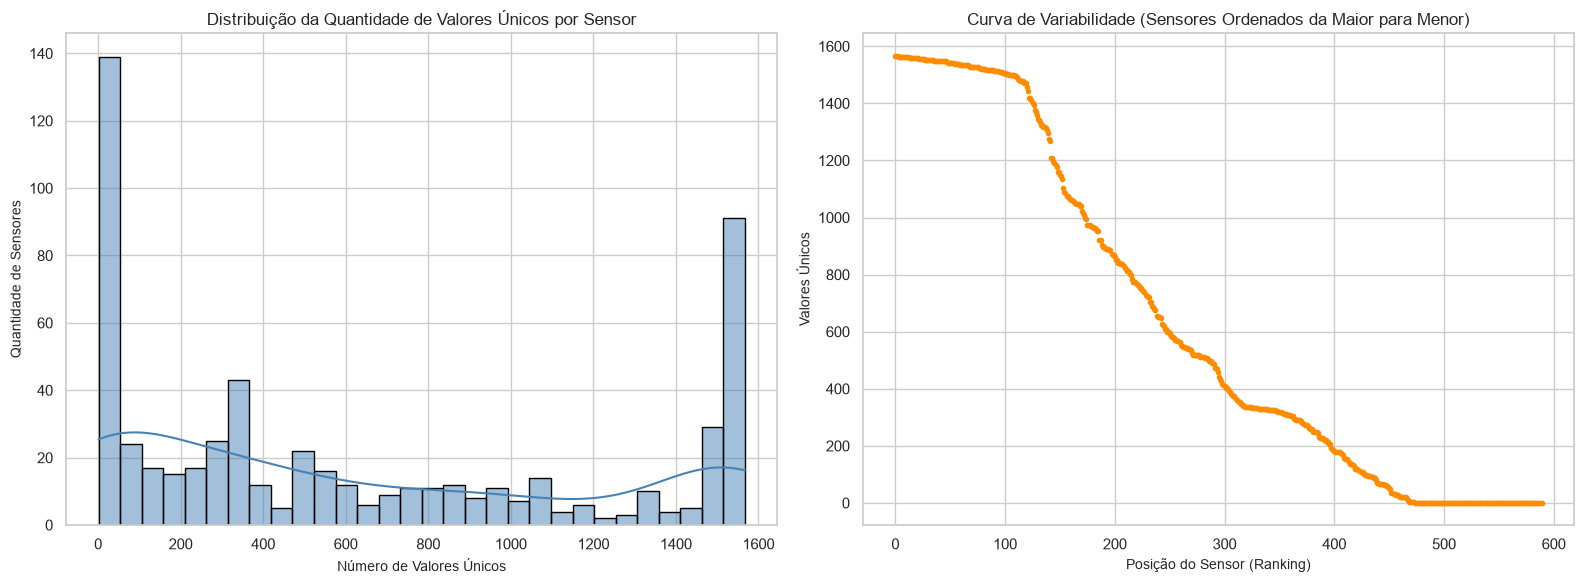

Estatísticas dos valores únicos por sensor:
count     590.000000
mean      631.540678
std       581.619974
min         1.000000
25%        68.000000
50%       450.000000
75%      1172.000000
max      1567.000000
dtype: float64


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Seleciona apenas as colunas de sensores e calcula os valores únicos
sensor_cols = [col for col in df_features.columns if col.startswith("Sensor_")]
unique_counts = df_features[sensor_cols].nunique().sort_values(ascending=False)

# 2. Configura a área do gráfico (2 subplots lado a lado)
plt.figure(figsize=(16, 6))
sns.set_theme(style="whitegrid")

# --- Gráfico 1: Histograma da Variabilidade ---
plt.subplot(1, 2, 1)
sns.histplot(
    unique_counts, bins=30, color="steelblue", edgecolor="black", kde=True
)
plt.title(
    "Distribuição da Quantidade de Valores Únicos por Sensor", fontsize=12
)
plt.xlabel("Número de Valores Únicos", fontsize=10)
plt.ylabel("Quantidade de Sensores", fontsize=10)

# --- Gráfico 2: Curva Ordenada de Todos os Sensores ---
plt.subplot(1, 2, 2)
plt.plot(
    range(len(unique_counts)),
    unique_counts.values,
    color="darkorange",
    marker="o",
    markersize=3,
    linestyle="none",
)
plt.title(
    "Curva de Variabilidade (Sensores Ordenados da Maior para Menor)",
    fontsize=12,
)
plt.xlabel("Posição do Sensor (Ranking)", fontsize=10)
plt.ylabel("Valores Únicos", fontsize=10)

# Ajusta o layout e exibe
plt.tight_layout()
plt.show()

# Exibe um resumo estatístico rápido no console
print(f"Estatísticas dos valores únicos por sensor:")
print(unique_counts.describe())